# **AI ML PROJECT ZYNEX SOLUTIONS BATCH 05**

### **NAME: KHAWAJA MOHAMMAD BILAL**

## **TOPIC: PREDICTING FUEL EFFICENCY**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:


df = pd.read_csv("auto-mpg.csv")

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [5]:
# First five rows
display(df.head())

# Dataset shape
print("Shape:", df.shape)

# Column names
print("Columns:", df.columns.tolist())

# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Missing values
print(df.isnull().sum())

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


Shape: (398, 9)
Columns: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year', 'origin', 'car name']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB


,mpg,cylinders,displacement,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64


In [6]:
# Replace question marks with missing values
df = df.replace("?", np.nan)

# Convert numerical columns
numeric_columns = [
    "mpg",
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model year",
    "origin"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill missing numerical values with median
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# Remove duplicate rows
df = df.drop_duplicates()

print("Data cleaning completed!")
print(df.isnull().sum())

Data cleaning completed!
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64


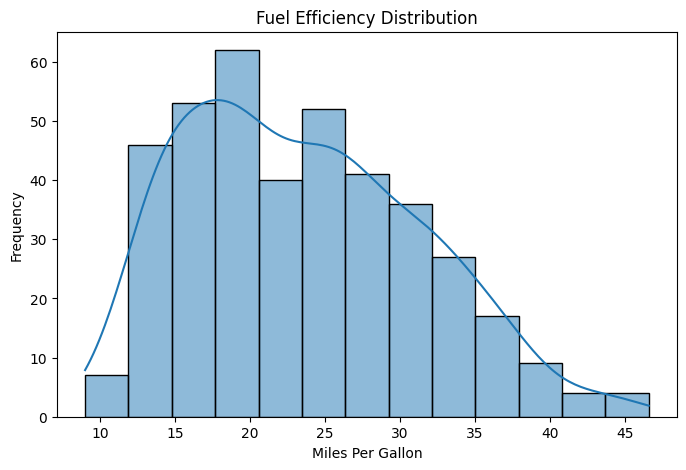

In [7]:
plt.figure(figsize=(8,5))

sns.histplot(df["mpg"], kde=True)

plt.title("Fuel Efficiency Distribution")
plt.xlabel("Miles Per Gallon")
plt.ylabel("Frequency")

plt.show()

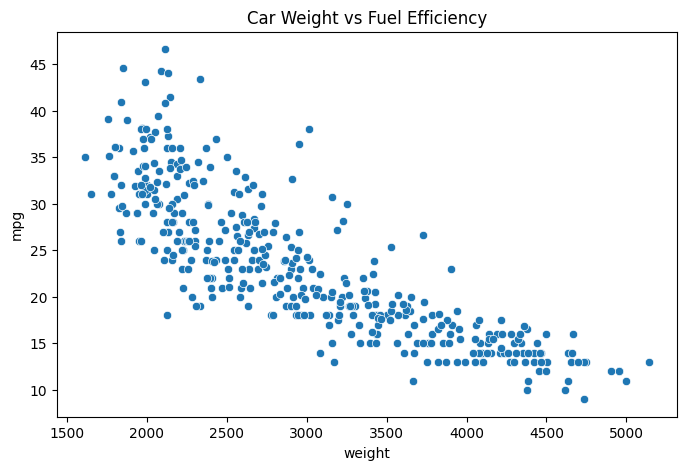

In [8]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="weight",
    y="mpg"
)

plt.title("Car Weight vs Fuel Efficiency")

plt.show()

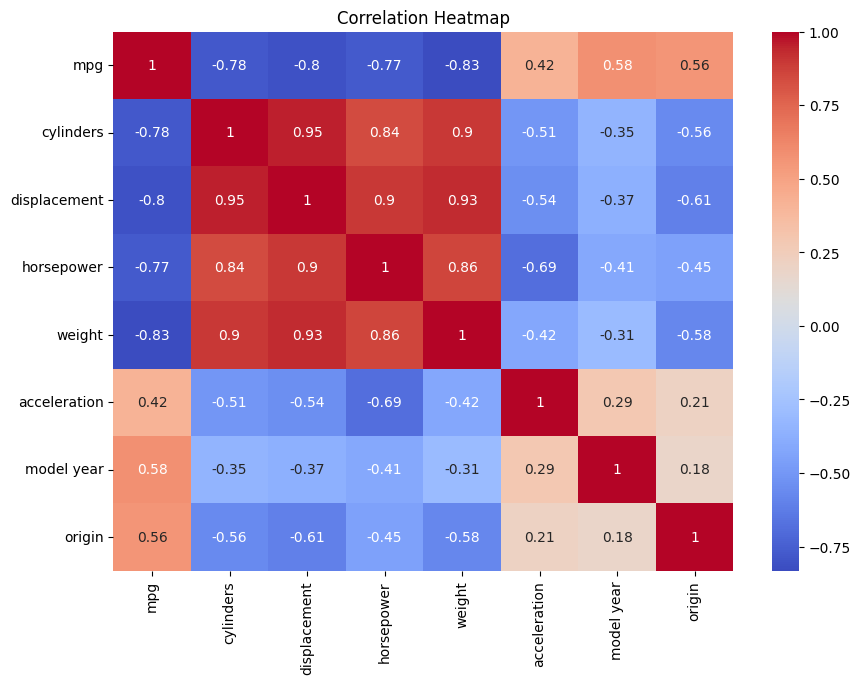

In [9]:
plt.figure(figsize=(10,7))

sns.heatmap(
    df[numeric_columns].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [10]:
# Input features
X = df[
    [
        "cylinders",
        "displacement",
        "horsepower",
        "weight",
        "acceleration",
        "model year",
        "origin"
    ]
]

# Target variable
y = df["mpg"]

print("Features selected successfully!")

Features selected successfully!


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (318, 7)
Testing data: (80, 7)


**Train Machine Learning Models**

In [12]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Linear Regression trained!")

Linear Regression trained!


In [13]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

print("Decision Tree trained!")

Decision Tree trained!


In [14]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest trained!")

Random Forest trained!


## **Model Evaluation**

In [15]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

models = {
    "Linear Regression": lr_predictions,
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions
}

results = []

for name, pred in models.items():

    mae = mean_absolute_error(y_test, pred)

    mse = mean_squared_error(y_test, pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, pred)

    results.append([
        name, mae, mse, rmse, r2
    ])

results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "MSE", "RMSE", "R2 Score"]
)

display(results_df.round(3))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,2.255,8.198,2.863,0.848
1,Decision Tree,2.284,10.913,3.303,0.797
2,Random Forest,1.577,4.584,2.141,0.915


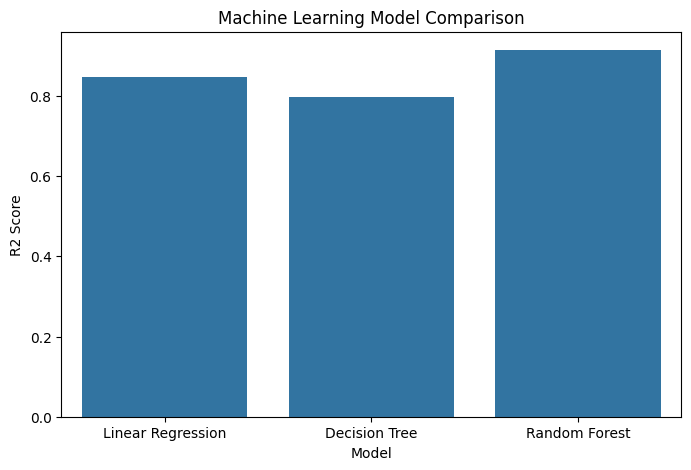

In [16]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Machine Learning Model Comparison")

plt.show()

In [17]:
# Example new car
new_car = pd.DataFrame([{
    "cylinders": 4,
    "displacement": 140,
    "horsepower": 90,
    "weight": 2500,
    "acceleration": 15,
    "model year": 80,
    "origin": 1
}])

prediction = rf_model.predict(new_car)

print(
    "Predicted Fuel Efficiency:",
    round(prediction[0], 2),
    "MPG"
)

Predicted Fuel Efficiency: 30.09 MPG


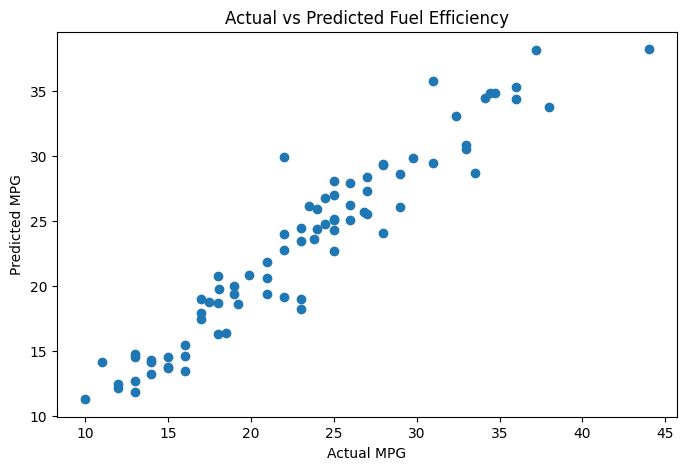

In [18]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, rf_predictions)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")

plt.title("Actual vs Predicted Fuel Efficiency")

plt.show()

In [19]:
import joblib

joblib.dump(rf_model, "fuel_efficiency_model.pkl")

print("Model saved successfully!")

Model saved successfully!
